<div dir="rtl" style="text-align: right">

# ניקוי עמודות הנהג, ההיסטוריה והגאוגרפיה (עמודות A עד M)
מחברת עבודה של ליעד. לכל עמודה: מה היא, האם ידועה ביום החתימה, בדיקות, מסקנה, וחוק ניקוי.
בסוף המחברת: פונקציות העזר, הפונקציה clean_driver_cols, ובדיקות קיצון.

</div>

In [1]:
# ייבוא ספריות טעינת הדאטה וקביעת מצב אקראי קבוע
import pandas as pd
import numpy as np

RANDOM_STATE = 42  # Required by the assignment
df = pd.read_csv("dataset.csv")
print(df.shape)

(45000, 30)


<div dir="rtl" style="text-align: right">

## עמודה A: customer_id_hash
מזהה לקוח מוצפן. לכל נהג יש קוד ייחודי, ולכן אין בעמודה מידע שיכול לעזור בחיזוי, ונהג חדש יגיע תמיד עם קוד שהמודל לא ראה. העמודה תוסר.

</div>

In [2]:
# בדיקה שכל מזהה לקוח מופיע פעם אחת בלבד
print("Unique IDs:", df["customer_id_hash"].is_unique)

Unique IDs: True


<div dir="rtl" style="text-align: right">

## עמודה B: agent_code
קוד הסוכן שמכר את הפוליסה. הסוכן ידוע ביום החתימה ולכן אין כאן דליפת מידע.
נבדוק את אחידות הפורמט, את מספר הסוכנים, את כמות הנהגים לכל סוכן ואת הקשר לעלות התביעות.

</div>

In [3]:
# בדיקת ערכים חסרים ובדיקה שכל הקודים באותו פורמט של אות ושלוש ספרות
print("Missing:", df["agent_code"].isna().sum())
print("Valid format:", df["agent_code"].str.match(r"^A\d{3}$").mean())

Missing: 0
Valid format: 1.0


In [4]:
# כמה סוכנים יש וכמה נהגים יש לכל סוכן
counts = df["agent_code"].value_counts()
print("Number of agents:", counts.size)
counts.describe()

Number of agents: 300


count     300.000000
mean      150.000000
std       235.319423
min        35.000000
25%        64.000000
50%        87.000000
75%       140.250000
max      2791.000000
Name: count, dtype: float64

In [5]:
# עלות ממוצעת לפי סוכן אצל הסוכנים הקטנים לעומת הגדולים
agent_stats = df.groupby("agent_code")["annual_claim_cost"].agg(["mean", "count"])
print("Small agents under 100 drivers")
print(agent_stats[agent_stats["count"] < 100]["mean"].describe().round(0))
print("\nLarge agents with 200 drivers or more")
print(agent_stats[agent_stats["count"] >= 200]["mean"].describe().round(0))

Small agents under 100 drivers
count     179.0
mean     3016.0
std       955.0
min       726.0
25%      2370.0
50%      2864.0
75%      3605.0
max      6641.0
Name: mean, dtype: float64

Large agents with 200 drivers or more
count      45.0
mean     3013.0
std       426.0
min      2135.0
25%      2764.0
50%      3048.0
75%      3218.0
max      4070.0
Name: mean, dtype: float64


In [6]:
# בדיקה האם כל סוכן עובד במדינה אחת או בכמה מדינות
df.groupby("agent_code")["country"].nunique().describe()

count    300.000000
mean       9.896667
std        0.315681
min        8.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       10.000000
Name: country, dtype: float64

In [7]:
# בדיקת ערבוב: מערבבים את העלויות בין הנהגים ובודקים אם הפיזור האמיתי בין הסוכנים גדול ממה שמקריות יוצרת
rng = np.random.default_rng(RANDOM_STATE)
y = df["annual_claim_cost"].values
agents = df["agent_code"].values

real_spread = pd.Series(y).groupby(agents).mean().std()
shuffled_spreads = [pd.Series(rng.permutation(y)).groupby(agents).mean().std() for _ in range(300)]

print("Real spread between agents:     ", round(real_spread))
print("Average spread after shuffling: ", round(np.mean(shuffled_spreads)))
print("Share of shuffles with larger spread:", round(np.mean(np.array(shuffled_spreads) >= real_spread), 2))

Real spread between agents:      807
Average spread after shuffling:  803
Share of shuffles with larger spread: 0.44


<div dir="rtl" style="text-align: right">

### מסקנה לגבי agent_code
העמודה נקייה, ללא חסרים ובפורמט אחיד. יש 300 סוכנים, רובם קטנים, וכמעט כל סוכן עובד בכל המדינות.
בבדיקת ערבוב, הפיזור האמיתי בין הסוכנים (807) דומה לפיזור שמתקבל כשמערבבים את העלויות באקראי (803), וב-44% מהערבובים הוא אף גדול יותר. כלומר, ההבדלים בין הסוכנים מוסברים במקריות.
לכן העמודה תוסר. הוספתה הייתה מוסיפה למודל 300 עמודות ללא מידע ומגדילה את הסיכון ל-overfitting.

</div>

In [8]:
# רשימת העמודות מהחלק שלי שיוסרו מהמודל
DROP_COLS_DRIVER = ["customer_id_hash", "agent_code"]

<div dir="rtl" style="text-align: right">

## עמודה C: country
מדינת הפוליסה. זו עמודה קטגוריאלית עם 10 מדינות. המדינה ידועה ביום החתימה ולכן אין כאן דליפת מידע.
נבדוק את אחידות הערכים, את כמות הנהגים בכל מדינה ואת הקשר בין המדינה לעלות התביעות.

</div>

In [9]:
# בדיקת ערכים חסרים ורשימת המדינות עם מספר הנהגים בכל אחת
print("Missing:", df["country"].isna().sum())
df["country"].value_counts()

Missing: 0


country
US    9907
DE    5789
GB    5394
FR    4536
IT    4508
IL    4455
ES    3739
BR    3156
PL    2181
JP    1335
Name: count, dtype: int64

In [10]:
# השוואת עלות התביעות בין המדינות לפי שלושה מדדים
country_stats = df.groupby("country")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3).sort_values("avg_cost")
country_stats

,avg_cost,share_with_claim,share_expensive,drivers
country,,,,
JP,973.666,0.196,0.022,1335
BR,1197.146,0.412,0.013,3156
PL,1247.617,0.379,0.017,2181
ES,1625.003,0.347,0.031,3739
GB,1976.434,0.266,0.059,5394
IT,2049.465,0.350,0.053,4508
FR,2130.829,0.301,0.058,4536
DE,2819.795,0.297,0.093,5789
IL,2993.003,0.369,0.090,4455


<div dir="rtl" style="text-align: right">

### מסקנה לגבי country
העמודה נקייה, עם 10 מדינות וללא ערכים חסרים. יש הבדל גדול ועקבי בעלות בין המדינות, פי 6.7 בין יפן לארה"ב, ובכל מדינה יש אלפי נהגים ולכן ההבדל אינו מקרי. העמודה תישאר.
יש מדינות עם הרבה תביעות קטנות, כמו ברזיל, ומדינות עם תביעות גדולות, כמו ארה"ב.
בפונקציית הניקוי נוסיף חוק שמאחד כתיבה, כדי להגן מפני וריאנטים בקובץ הבדיקה. את המרת המדינה לעמודות 0 ו-1 נבצע בתוך ה-Pipeline.

</div>

<div dir="rtl" style="text-align: right">

## עמודה D: area_type
סוג אזור המגורים: עיר, פרבר או כפר. זו עמודה קטגוריאלית שידועה ביום החתימה.
נבדוק את אחידות הערכים, את הקשר לעלות התביעות ואת הקשר לעמודת צפיפות האוכלוסייה.

</div>

In [11]:
# בדיקת ערכים חסרים ורשימת סוגי האזורים עם מספר הנהגים בכל אחד
print("Missing:", df["area_type"].isna().sum())
df["area_type"].value_counts()

Missing: 0


area_type
urban       18329
suburban    18086
rural        8585
Name: count, dtype: int64

In [12]:
# השוואת עלות התביעות בין סוגי האזורים לפי שלושה מדדים
df.groupby("area_type")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
area_type,,,,
rural,3751.261,0.297,0.121,8585
suburban,3062.542,0.344,0.095,18086
urban,2711.231,0.383,0.077,18329


In [13]:
# בדיקה האם סוג האזור מתאים לצפיפות האוכלוסייה שרשומה לנהג
df.groupby("area_type")["region_density"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
area_type,,,,,,,,
rural,8585.0,74.0,59.0,4.0,35.0,58.0,93.0,602.0
suburban,18086.0,991.0,563.0,121.0,611.0,863.0,1227.0,8205.0
urban,18329.0,3619.0,2413.0,299.0,1970.0,2997.0,4541.0,20000.0


<div dir="rtl" style="text-align: right">

### מסקנה לגבי area_type
העמודה נקייה, עם שלושה ערכים וללא חסרים. בעיר יש יותר תביעות אך קטנות יותר, ובכפר פחות תביעות אך יקרות יותר, ולכן העמודה משפיעה על העלות ותישאר.
הצפיפות מתאימה לסוג האזור ברוב המקרים. החפיפה הקטנה בקצוות נובעת כנראה מהגדרות שונות בין מדינות ואינה שגיאה.
בפונקציית הניקוי נוסיף חוק שמאחד כתיבה. את המרת האזור לעמודות 0 ו-1 נבצע בתוך ה-Pipeline.

</div>

<div dir="rtl" style="text-align: right">

## עמודה E: region_density
צפיפות האוכלוסייה באזור המגורים, כלומר מספר התושבים לקמ"ר. זו עמודה מספרית שידועה ביום החתימה.
נבדוק ערכים חסרים וערכים לא הגיוניים, את צורת ההתפלגות ואת הקשר לעלות התביעות.

</div>

In [14]:
# בדיקת ערכים חסרים וסטטיסטיקה תיאורית של הצפיפות
print("Missing:", df["region_density"].isna().sum())
df["region_density"].describe().round(0)

Missing: 0


count    45000.0
mean      1887.0
std       2161.0
min          4.0
25%        498.0
50%       1151.0
75%       2593.0
max      20000.0
Name: region_density, dtype: float64

In [15]:
# בדיקת הערכים הגבוהים ביותר וכמה נהגים יש בערך המקסימלי
print("Drivers at max value 20000:", (df["region_density"] == 20000).sum())
df["region_density"].sort_values(ascending=False).head(10).values

Drivers at max value 20000: 21


array([20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000,
       20000])

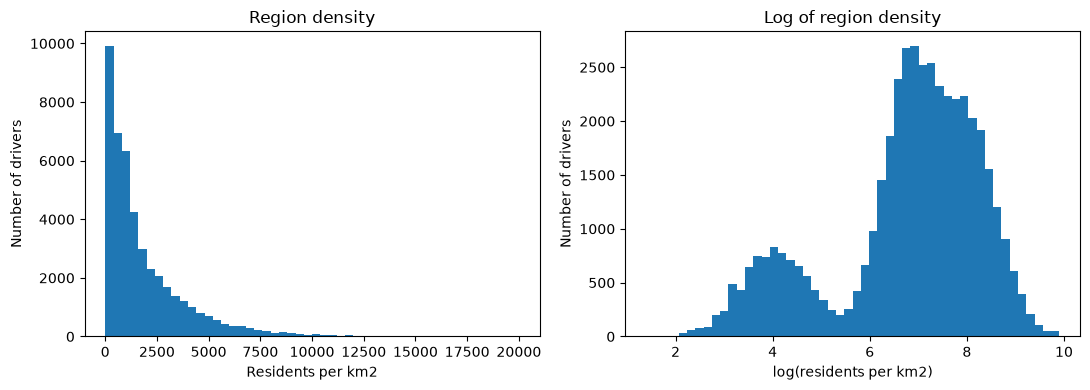

In [16]:
# היסטוגרמה של הצפיפות בסקאלה רגילה ובסקאלה לוגריתמית
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["region_density"], bins=50)
axes[0].set_title("Region density")
axes[0].set_xlabel("Residents per km2")
axes[0].set_ylabel("Number of drivers")

axes[1].hist(np.log(df["region_density"]), bins=50)
axes[1].set_title("Log of region density")
axes[1].set_xlabel("log(residents per km2)")
axes[1].set_ylabel("Number of drivers")
plt.tight_layout()
plt.show()

In [17]:
# חלוקת הנהגים לחמש קבוצות שוות לפי צפיפות והשוואת עלות התביעות בין הקבוצות
density_group = pd.qcut(df["region_density"], 5)
df.groupby(density_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
region_density,,,,
"(3.999, 315.0]",3786.514,0.302,0.122,9003
"(315.0, 863.0]",3348.248,0.355,0.106,9020
"(863.0, 1556.0]",2804.753,0.347,0.086,8979
"(1556.0, 3079.0]",2678.152,0.364,0.075,9000
"(3079.0, 20000.0]",2634.969,0.387,0.074,8998


<div dir="rtl" style="text-align: right">

### מסקנה לגבי region_density
העמודה ללא חסרים וללא ערכים שליליים. 21 נהגים בערך 20,000, כולם באזור עירוני, וזו כנראה תקרת רישום ולא שגיאה.
ההתפלגות מוטה ימינה עם זנב ארוך. בסקאלה לוגריתמית מופיעות שתי קבוצות, כפרים מול ערים ופרברים, בהתאמה ל-area_type.
העלות יורדת ככל שהצפיפות עולה, וההשפעה חזקה בעיקר באזורים דלילים. מועמד לפיצ'ר מהונדס: לוגריתם של הצפיפות.
בפונקציית הניקוי נוסיף חוק שמוודא שהערך מספרי וחיובי, וערך לא תקין יהפוך לחסר.

</div>

<div dir="rtl" style="text-align: right">

## עמודה F: winter_severity
חומרת החורף באזור המגורים, בסולם 0 עד 10 לפי מילון השדות, כאשר 0 הוא כמעט ללא חורף. זו עמודה מספרית שידועה ביום החתימה.
נבדוק שכל הערכים בטווח החוקי, שהערכים הגיוניים לפי מדינה, ואת הקשר לעלות התביעות.

</div>

In [18]:
# בדיקת ערכים חסרים ובדיקה שכל הערכים בטווח החוקי של אפס עד עשר
print("Missing:", df["winter_severity"].isna().sum())
print("Out of range:", ((df["winter_severity"] < 0) | (df["winter_severity"] > 10)).sum())
df["winter_severity"].describe().round(2)

Missing: 0
Out of range: 0


count    45000.00
mean         3.46
std          2.21
min          0.00
25%          1.70
50%          3.30
75%          5.00
max         10.00
Name: winter_severity, dtype: float64

In [19]:
# בדיקה האם חומרת החורף הגיונית לפי מדינה
df.groupby("country")["winter_severity"].agg(["mean", "min", "max"]).round(1).sort_values("mean")

,mean,min,max
country,,,
BR,0.6,0.0,2.3
IL,1.1,0.0,3.6
ES,2.1,0.0,6.5
GB,3.1,0.0,6.6
IT,3.1,0.0,8.8
FR,3.6,0.0,9.5
JP,4.5,0.0,10.0
US,4.6,0.0,10.0
DE,5.1,0.0,10.0


In [20]:
# חלוקת הנהגים לקבוצות לפי חומרת החורף והשוואת עלות התביעות
winter_group = pd.cut(df["winter_severity"], bins=[-0.01, 1, 3, 5, 7, 10])
df.groupby(winter_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
winter_severity,,,,
"(-0.01, 1.0]",2248.726,0.373,0.060,7311
"(1.0, 3.0]",2727.048,0.341,0.080,13320
"(3.0, 5.0]",2968.202,0.331,0.091,13573
"(5.0, 7.0]",3902.434,0.364,0.126,7789
"(7.0, 10.0]",4602.491,0.397,0.147,3007


In [21]:
# השוואת הקשר בין חומרת החורף לעלות בכל הדאטה לעומת בתוך כל מדינה בנפרד
print("All drivers:", round(df["winter_severity"].corr(df["annual_claim_cost"]), 3))
for c in ["US", "DE", "PL", "IL"]:
    d = df[df["country"] == c]
    print(c, round(d["winter_severity"].corr(d["annual_claim_cost"]), 3))

All drivers: 0.087
US 0.037
DE 0.021
PL 0.062
IL 0.029


<div dir="rtl" style="text-align: right">

### מסקנה לגבי winter_severity
העמודה ללא חסרים, וכל הערכים בטווח החוקי 0 עד 10. הערכים הגיוניים לפי מדינה: ברזיל וישראל מתונות, פולין וגרמניה קרות.
ככל שהחורף קשה יותר העלות הממוצעת ואחוז הנהגים היקרים עולים, אך אחוז הנהגים שתובעים כמעט לא משתנה. כלומר, בחורף קשה התאונות יקרות יותר ולא בהכרח שכיחות יותר.
חלק מהקשר נובע מהמדינה (משתנה מבלבל): המתאם בכל הדאטה הוא 0.087, ובתוך כל מדינה רק 0.021 עד 0.062, אך עדיין חיובי. העמודה תישאר, והמודל יפריד בין השפעת המדינה להשפעת החורף.
בפונקציית הניקוי נוסיף חוק שמוודא שהערך מספרי ובטווח 0 עד 10, וערך מחוץ לטווח יהפוך לחסר.

</div>

<div dir="rtl" style="text-align: right">

## עמודה G: driver_age
גיל הנהג בשנים. זו עמודה מספרית שידועה ביום החתימה, ועליה מבוססים סעיפי חקירת הנתונים 2.3 ו-2.4.
נבדוק שהגילאים חוקיים והגיוניים, את התפלגות הגילאים, ואת הקשר בין הגיל לעלות התביעות.

</div>

In [22]:
# בדיקת ערכים חסרים סוג הנתונים והגיל הנמוך והגבוה ביותר
print("Missing:", df["driver_age"].isna().sum())
print("Type:", df["driver_age"].dtype)
print("Min age:", df["driver_age"].min(), "| Max age:", df["driver_age"].max())

Missing: 0
Type: int64
Min age: 18 | Max age: 90


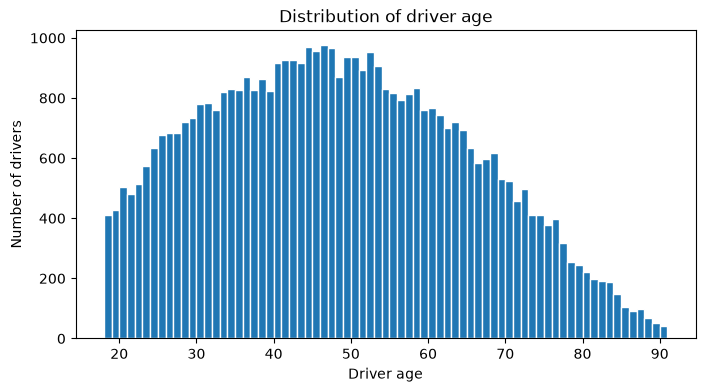

In [23]:
# היסטוגרמה של גילאי הנהגים
plt.figure(figsize=(8, 4))
plt.hist(df["driver_age"], bins=range(18, 92), edgecolor="white")
plt.title("Distribution of driver age")
plt.xlabel("Driver age")
plt.ylabel("Number of drivers")
plt.show()

In [24]:
# חלוקת הנהגים לקבוצות גיל והשוואת עלות התביעות
age_group = pd.cut(df["driver_age"], bins=[17, 24, 34, 44, 54, 64, 74, 90])
df.groupby(age_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
driver_age,,,,
"(17, 24]",5838.546,0.590,0.169,3542
"(24, 34]",3393.102,0.385,0.101,7473
"(34, 44]",2916.300,0.346,0.091,8871
"(44, 54]",2789.977,0.331,0.087,9219
"(54, 64]",2722.653,0.334,0.080,7642
"(64, 74]",1901.850,0.238,0.058,5262
"(74, 90]",2957.455,0.303,0.093,2991


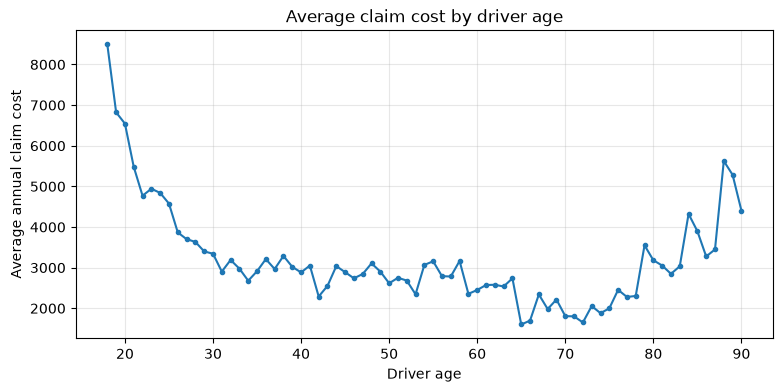

In [25]:
# גרף של העלות הממוצעת לכל גיל בנפרד
avg_by_age = df.groupby("driver_age")["annual_claim_cost"].mean()
plt.figure(figsize=(9, 4))
plt.plot(avg_by_age.index, avg_by_age.values, marker="o", markersize=3)
plt.title("Average claim cost by driver age")
plt.xlabel("Driver age")
plt.ylabel("Average annual claim cost")
plt.grid(alpha=0.3)
plt.show()

<div dir="rtl" style="text-align: right">

### מסקנה לגבי driver_age
העמודה ללא חסרים, וכל הגילאים חוקיים, בין 18 ל-90. רוב הנהגים בגילאי 40 עד 50, ומעל 85 יש מעט נהגים (348), ולכן הממוצעים שם רועשים.
הקשר בין הגיל לעלות הוא בצורת U: צעירים בני 18 עד 24 יקרים פי שניים מגילאי הביניים, בעיקר בגלל תדירות (59% תובעים), העלות הנמוכה ביותר בגילאי 65 עד 74, ומעל 75 היא עולה שוב.
מודל לינארי עם גיל בלבד לא יוכל ללמוד צורה כזו. לכן מועמדים לפיצ'רים מהונדסים: גיל בריבוע, דגל נהג צעיר, וקבוצות גיל.
בפונקציית הניקוי נוסיף חוק שמוודא שהגיל מספרי ובטווח סביר של 16 עד 100, וערך מחוץ לטווח יהפוך לחסר.

</div>

<div dir="rtl" style="text-align: right">

## עמודה H: gender
מין הנהג. לפי מילון השדות הערכים האפשריים הם M לגבר ו-F לאישה. זו עמודה קטגוריאלית שידועה ביום החתימה.
נבדוק את אחידות הכתיבה, נאחד את הערכים לשני ערכים תקניים, ונבדוק את הקשר לעלות התביעות.

</div>

In [26]:
# כל הערכים השונים שמופיעים בעמודה כולל ערכים חסרים
df["gender"].value_counts(dropna=False)

gender
M         23624
F         20224
Male        232
m           195
female      187
male        187
f           177
Female      174
Name: count, dtype: int64

In [27]:
# הצגת כל ערך עם גרשיים כדי לחשוף רווחים מוסתרים לפני או אחרי הטקסט
df["gender"].map(repr).value_counts()

gender
'M'         23624
'F'         20224
'Male'        232
'm'           195
'female'      187
'male'        187
'f'           177
'Female'      174
Name: count, dtype: int64

In [28]:
# איחוד הכתיבה לשני ערכים תקניים לפי מילון מיפוי ובדיקה שלא נשארו ערכים לא מוכרים
gender_map = {"m": "M", "male": "M", "f": "F", "female": "F"}
gender_clean = df["gender"].str.strip().str.lower().map(gender_map)
print("Unmapped values:", gender_clean.isna().sum())
gender_clean.value_counts()

Unmapped values: 0


gender
M    24238
F    20762
Name: count, dtype: int64

In [29]:
# אחוז השורות שנכתבו בצורה לא תקנית בכל מדינה כדי לבדוק אם הבעיה מגיעה ממקור אחד
nonstandard = ~df["gender"].isin(["M", "F"])
print("Non standard rows:", nonstandard.sum())
nonstandard.groupby(df["country"]).mean().round(3).sort_values()

Non standard rows: 1152


country
JP    0.023
DE    0.024
FR    0.024
PL    0.024
GB    0.025
ES    0.025
IT    0.026
IL    0.026
BR    0.027
US    0.028
Name: gender, dtype: float64

In [30]:
# השוואת עלות התביעות בין גברים לנשים אחרי האיחוד
df.groupby(gender_clean)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
gender,,,,
F,2745.651,0.336,0.082,20762
M,3312.264,0.363,0.101,24238


<div dir="rtl" style="text-align: right">

### מסקנה לגבי gender
בעמודה 8 צורות כתיבה שונות לשני ערכים, ו-1,152 שורות כתובות בצורה לא תקנית, מפוזרות באופן אחיד בין המדינות (2.3% עד 2.8% בכל מדינה). אין ערכים חסרים.
האיחוד נעשה לפי מילון מיפוי מפורש ולא לפי האות הראשונה, כדי שערך לא מוכר יהפוך לחסר ולא יסווג בטעות.
גברים עולים בממוצע כ-21% יותר מנשים, גם בגלל מעט יותר תביעות וגם בגלל יותר תביעות יקרות. העמודה תישאר, וההוגנות של השימוש בה תידון בסעיף 7.

</div>

<div dir="rtl" style="text-align: right">

## עמודה I: marital_status
מצב משפחתי. לפי מילון השדות הערכים האפשריים הם single, married, divorced ו-widowed. זו עמודה קטגוריאלית שידועה ביום החתימה.
נבדוק את אחידות הכתיבה ואת הקשר לעלות התביעות, ונבדוק האם הקשר נובע מהמצב המשפחתי עצמו או מהגיל.

</div>

In [31]:
# כל הערכים השונים בעמודה עם גרשיים כדי לחשוף רווחים מוסתרים
print("Missing:", df["marital_status"].isna().sum())
df["marital_status"].map(repr).value_counts()

Missing: 0


marital_status
'married'     23290
'single'      13108
'divorced'     5550
'widowed'      3052
Name: count, dtype: int64

In [32]:
# השוואת עלות התביעות בין מצבים משפחתיים
df.groupby("marital_status")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3).sort_values("avg_cost")

,avg_cost,share_with_claim,share_expensive,drivers
marital_status,,,,
widowed,2523.569,0.290,0.081,3052
married,2698.835,0.318,0.083,23290
divorced,3029.545,0.350,0.093,5550
single,3808.063,0.424,0.112,13108


In [33]:
# הגיל הממוצע והחציוני בכל מצב משפחתי
df.groupby("marital_status")["driver_age"].agg(["mean", "median", "min"]).round(1)

,mean,median,min
marital_status,,,
divorced,52.4,52.0,21
married,51.0,50.0,18
single,36.6,33.0,18
widowed,66.0,68.0,36


In [34]:
# עלות ממוצעת לפי מצב משפחתי בתוך כל קבוצת גיל בנפרד
age_group = pd.cut(df["driver_age"], bins=[17, 24, 34, 54, 74, 90])
df.pivot_table(index=age_group, columns="marital_status",
               values="annual_claim_cost", aggfunc="mean", observed=True).round(0)

marital_status,divorced,married,single,widowed
driver_age,,,,
"(17, 24]",6377.0,5621.0,5856.0,NaN
"(24, 34]",3690.0,3188.0,3518.0,NaN
"(34, 54]",3158.0,2685.0,3108.0,2681.0
"(54, 74]",2552.0,2371.0,2304.0,2353.0
"(74, 90]",3760.0,2873.0,2805.0,2802.0


<div dir="rtl" style="text-align: right">

### מסקנה לגבי marital_status
העמודה נקייה, עם ארבעה ערכים וללא חסרים. בהשוואה כללית רווקים יקרים מנשואים בכ-41%, אך הרווקים צעירים בהרבה (גיל ממוצע 37 לעומת 51), ולכן רוב ההבדל נובע מהגיל (משתנה מבלבל).
בתוך אותה קבוצת גיל הפער בין רווקים לנשואים קטן ל-10% עד 16% בגילאי 25 עד 54, ונעלם בגילאים המבוגרים. גרושים יקרים מנשואים כמעט בכל קבוצת גיל.
העמודה תישאר, והמודל יפריד בין השפעת הגיל להשפעת המצב המשפחתי. אין אלמנים מתחת לגיל 36 בדאטה.
בפונקציית הניקוי נוסיף חוק שמאחד כתיבה ומשאיר רק את ארבעת הערכים החוקיים, וערך אחר יהפוך לחסר.

</div>

<div dir="rtl" style="text-align: right">

## עמודה J: license_years
מספר השנים מאז קבלת רישיון הנהיגה. זו עמודה מספרית שידועה ביום החתימה.
נבדוק ערכים חסרים ושליליים, נבדוק האם ותק הרישיון אפשרי ביחס לגיל הנהג, ונבדוק את הקשר לעלות התביעות.

</div>

In [35]:
# בדיקת ערכים חסרים ושליליים וסטטיסטיקה תיאורית של ותק הרישיון
print("Missing:", df["license_years"].isna().sum())
print("Negative:", (df["license_years"] < 0).sum())
df["license_years"].describe().round(1)

Missing: 0
Negative: 0


count    45000.0
mean        28.9
std         16.9
min          0.0
25%         15.0
50%         28.0
75%         41.0
max         95.0
Name: license_years, dtype: float64

In [36]:
# חישוב הגיל שבו כל נהג קיבל רישיון, כלומר הגיל פחות ותק הרישיון
age_at_license = df["driver_age"] - df["license_years"]
print("Drivers who got a license before age 16:", (age_at_license < 16).sum())
age_at_license.value_counts().sort_index().head(15)

Drivers who got a license before age 16: 153


-10       16
-9        12
-8        12
-7        13
-6        16
-5        23
-4        16
-3        19
-2        14
-1        12
 17    12617
 18    11657
 19     7733
 20     4807
 21     2788
Name: count, dtype: int64

In [37]:
# הצגת דוגמאות של נהגים עם ותק רישיון בלתי אפשרי
impossible = age_at_license < 16
df.loc[impossible, ["driver_age", "license_years", "country"]].head(10)

,driver_age,license_years,country
403,30,33,US
468,49,56,ES
476,33,38,JP
645,72,78,FR
730,46,47,IT
1379,70,77,US
1438,24,26,US
1952,89,94,US
3067,58,68,ES
3493,54,62,IL


In [38]:
# השוואת עלות התביעות לפי ותק הרישיון
license_group = pd.cut(df["license_years"], bins=[-1, 1, 3, 5, 10, 20, 40, 95])
df.groupby(license_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,drivers
license_years,,,
"(-1, 1]",6907.029,0.633,1643
"(1, 3]",5344.811,0.545,1066
"(3, 5]",4544.041,0.513,1159
"(5, 10]",3710.294,0.417,3507
"(10, 20]",2927.955,0.349,8213
"(20, 40]",2813.561,0.336,17549
"(40, 95]",2405.887,0.283,11863


In [39]:
# בדיקה האם לוותק הרישיון יש השפעה משלו מעבר לגיל, רק בקרב נהגים מתחת לגיל שלושים
young = df[df["driver_age"] < 30]
print("Correlation between age and license years:", round(df["driver_age"].corr(df["license_years"]), 3))
young.groupby(pd.cut(young["license_years"], bins=[-1, 1, 3, 6, 15]), observed=True)["annual_claim_cost"].agg(
    avg_cost="mean", drivers="count"
).round(0)

Correlation between age and license years: 0.976


,avg_cost,drivers
license_years,,
"(-1, 1]",7291.0,1433
"(1, 3]",5434.0,1001
"(3, 6]",4394.0,1658
"(6, 15]",3694.0,2931


<div dir="rtl" style="text-align: right">

### מסקנה לגבי license_years
העמודה ללא חסרים וללא ערכים שליליים. רוב הנהגים קיבלו רישיון בגיל 17 או 18, ואף נהג תקין לא קיבל רישיון לפני 17.
ב-153 שורות ותק הרישיון גדול מגיל הנהג עצמו, וזה בלתי אפשרי. הגילאים בשורות אלו רגילים, ולכן ההנחה היא שהשגיאה בוותק. הוותק בשורות אלו יהפוך לחסר, והשורות עצמן יישארו.
העלות יורדת בעקביות עם הוותק: נהג עם רישיון חדש עולה פי 2.9 מנהג ותיק. הקורלציה עם הגיל היא 0.976, אך גם בקרב נהגים מתחת לגיל 30 הוותק משנה את העלות כמעט פי 2, ולכן לעמודה יש מידע משלה והיא תישאר.
מועמדים לפיצ'רים מהונדסים: דגל נהג חדש (נבנה במחברת הפיצ'רים ונכנס למודל), והגיל בקבלת הרישיון (נבדק שם ונדחה, כי אין לו כיוון קבוע בתוך קבוצות הגיל).

</div>

<div dir="rtl" style="text-align: right">

## עמודה K: prior_claims_5y
מספר התביעות באשמת הנהג בחמש השנים האחרונות. לפי מילון השדות הערך חסר אצל נהגים חדשים ובמדינות עם רישום חלקי. זו עמודה שידועה ביום החתימה, כי היא מתארת את העבר.
נבדוק את הערכים ואת הסיבה לחוסרים, האם החוסר עצמו קשור לעלות, ואת הקשר בין מספר התביעות בעבר לעלות.

</div>

In [40]:
# כמות הערכים החסרים וכל הערכים האפשריים בעמודה
print("Missing:", df["prior_claims_5y"].isna().sum())
df["prior_claims_5y"].value_counts(dropna=False).sort_index()

Missing: 3142


prior_claims_5y
0.0    19708
1.0    11521
2.0     5267
3.0     2519
4.0     1236
5.0      678
6.0      929
NaN     3142
Name: count, dtype: int64

In [41]:
# אחוז החוסרים לפי ותק הרישיון כדי לבדוק את ההסבר של נהגים חדשים
missing_prior = df["prior_claims_5y"].isna()
missing_prior.groupby(df["license_years"].clip(upper=6)).mean().round(3)

license_years
0    1.000
1    0.053
2    0.035
3    0.052
4    0.034
5    0.051
6    0.045
Name: prior_claims_5y, dtype: float64

In [42]:
# אחוז החוסרים לפי מדינה כדי לבדוק את ההסבר של רישום חלקי
missing_prior.groupby(df["country"]).mean().round(3).sort_values()

country
JP    0.043
DE    0.045
FR    0.046
GB    0.047
US    0.049
IL    0.053
IT    0.080
ES    0.082
PL    0.149
BR    0.206
Name: prior_claims_5y, dtype: float64

In [43]:
# עלות התביעות לפי מספר התביעות בעבר
df.groupby("prior_claims_5y")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
prior_claims_5y,,,,
0.0,1749.641,0.235,0.053,19708
1.0,2737.925,0.333,0.084,11521
2.0,4187.907,0.451,0.125,5267
3.0,5192.204,0.547,0.160,2519
4.0,7361.858,0.648,0.225,1236
5.0,7978.156,0.732,0.239,678
6.0,10009.743,0.841,0.332,929


In [44]:
# השוואת עלות בין נהגים שהערך שלהם חסר לבין נהגים שהערך קיים, בנפרד לנהגים חדשים ולנהגים ותיקים
new_driver = df["license_years"] < 3
df.pivot_table(index=new_driver.rename("new_driver"), columns=missing_prior.rename("prior_missing"),
               values="annual_claim_cost", aggfunc="mean").round(0)

prior_missing,False,True
new_driver,,
False,2921.0,2035.0
True,5747.0,6851.0


### מסקנה לגבי prior_claims_5y
יש 3,142 ערכים חסרים, ושני מקורות שונים לחוסר. אצל כל הנהגים עם 0 שנות ותק הערך חסר, ובשאר הנהגים החוסר בולט בברזיל (21%) ובפולין (15%), בהתאם להסבר במילון השדות על נהגים חדשים ומדינות עם רישום חלקי.
הערכים שלמים בין 0 ל-6. ב-6 יש יותר נהגים מאשר ב-5, ולכן כנראה 6 מייצג 6 ומעלה.
זה הקשר החזק ביותר עד כה: נהג עם 6 תביעות בעבר עולה פי 5.7 מנהג ללא תביעות. החוסר עצמו מנבא, אך בכיוונים הפוכים: אצל נהגים חדשים החוסר יקר, ואצל ותיקים הוא זול.
חוקים: לנהג עם 0 שנות ותק ערך חסר הופך ל-0, כי לא יכלו להיות לו תביעות. ערך שלילי הופך לחסר, וערך מעל 6 הופך ל-6. שאר החוסרים יושלמו ב-Pipeline עם עמודת סימון חוסר.

<div dir="rtl" style="text-align: right">

## עמודה L: no_claims_years
מספר השנים הרצופות האחרונות ללא תביעה באשמת הנהג. בשלב בדיקת ה-Leakage כבר נמצא שהעמודה לא עודכנה בסוף השנה, ולכן מותר להשתמש בה.
נבדוק ערכים חסרים ולא הגיוניים, עקביות מול ותק הרישיון ומול מספר התביעות בעבר, ואת הקשר לעלות התביעות.

</div>

In [45]:
# בדיקת ערכים חסרים ושליליים וסטטיסטיקה תיאורית
print("Missing:", df["no_claims_years"].isna().sum())
print("Negative:", (df["no_claims_years"] < 0).sum())
df["no_claims_years"].describe().round(1)

Missing: 0
Negative: 0


count    45000.0
mean         6.8
std          8.1
min          0.0
25%          1.0
50%          3.0
75%         10.0
max         30.0
Name: no_claims_years, dtype: float64

In [46]:
# בדיקת עקביות מול ותק הרישיון והצגת מספר הנהגים בערכים הגבוהים ביותר
print("More claim free years than license years:", (df["no_claims_years"] > df["license_years"]).sum())
df["no_claims_years"].value_counts().sort_index().tail(8)

More claim free years than license years: 0


no_claims_years
23     326
24     265
25     260
26     228
27     215
28     189
29     187
30    1813
Name: count, dtype: int64

In [47]:
# בדיקת עקביות מול התביעות בעבר: מי שיש לו חמש שנים ומעלה ללא תביעה לא אמור להיות עם תביעות בחמש השנים האחרונות
pd.crosstab(df["no_claims_years"] >= 5, df["prior_claims_5y"] > 0,
            rownames=["5+ claim free years"], colnames=["has prior claims"])

has prior claims,False,True
5+ claim free years,,
False,3041,22150
True,19809,0


In [48]:
# השוואת עלות התביעות לפי מספר השנים ללא תביעה
nc_group = pd.cut(df["no_claims_years"], bins=[-1, 0, 1, 2, 4, 9, 19, 30])
df.groupby(nc_group, observed=True)["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,drivers
no_claims_years,,,
"(-1, 0]",5378.819,0.533,9168
"(0, 1]",4049.913,0.453,5765
"(1, 2]",3419.361,0.391,4235
"(2, 4]",2839.648,0.350,6023
"(4, 9]",2137.575,0.290,8433
"(9, 19]",1593.087,0.217,6884
"(19, 30]",901.589,0.131,4492


<div dir="rtl" style="text-align: right">

### מסקנה לגבי no_claims_years
העמודה ללא חסרים וללא שליליים, בטווח 0 עד 30. ב-30 יש קפיצה חדה במספר הנהגים (1,813 לעומת 187 ב-29), ולכן כנראה 30 מייצג 30 ומעלה.
העמודה עקבית לגמרי מול ותק הרישיון ומול התביעות בעבר: אף נהג אינו עם יותר שנים נקיות משנות רישיון, ואף נהג עם חמש שנים נקיות ומעלה אינו עם תביעות בחמש השנים האחרונות.
קשר חזק לעלות: נהג ללא שנים נקיות עולה פי 6 מנהג עם 20 עד 30 שנים נקיות. הערך 0 משותף לנהגים חדשים ולנהגים ותיקים שעשו תאונה לאחרונה, והמודל יבחין ביניהם בעזרת ותק הרישיון.
פיצ'ר מהונדס: היחס בין שנים ללא תביעה לבין שנות הרישיון (clean_ratio). נבדק במחברת הפיצ'רים ונכנס למודל, כפיצ'ר הנומרי המורכב.
חוקים: ערך שלילי או גדול מוותק הרישיון הופך לחסר, וערך מעל 30 הופך ל-30.

</div>

<div dir="rtl" style="text-align: right">

## עמודה M: violations_3y
מספר דוחות התנועה בשלוש השנים האחרונות. זו עמודה מספרית שמתארת את העבר ולכן ידועה ביום החתימה.
נבדוק ערכים חסרים ולא הגיוניים ואת הקשר לעלות, ונבדוק האם יש לעמודה מידע משלה מעבר לתביעות בעבר.

</div>

In [49]:
# בדיקת ערכים חסרים ושליליים וכל הערכים האפשריים בעמודה
print("Missing:", df["violations_3y"].isna().sum())
print("Negative:", (df["violations_3y"] < 0).sum())
df["violations_3y"].value_counts().sort_index()

Missing: 0
Negative: 0


violations_3y
0    30848
1    10677
2     2650
3      620
4      145
5       36
6       24
Name: count, dtype: int64

In [50]:
# השוואת עלות התביעות לפי מספר דוחות התנועה
df.groupby("violations_3y")["annual_claim_cost"].agg(
    avg_cost="mean",
    share_with_claim=lambda s: (s > 0).mean(),
    share_expensive=lambda s: (s > 10000).mean(),
    drivers="count",
).round(3)

,avg_cost,share_with_claim,share_expensive,drivers
violations_3y,,,,
0,2532.202,0.311,0.076,30848
1,3620.482,0.404,0.113,10677
2,5379.241,0.507,0.155,2650
3,7161.969,0.644,0.226,620
4,8259.131,0.717,0.248,145
5,11191.000,0.778,0.361,36
6,9281.667,0.917,0.333,24


In [51]:
# המתאם בין דוחות התנועה לבין שאר עמודות ההיסטוריה והגיל
df[["violations_3y", "prior_claims_5y", "no_claims_years", "driver_age"]].corr().round(2)["violations_3y"]

violations_3y      1.00
prior_claims_5y    0.26
no_claims_years   -0.16
driver_age        -0.14
Name: violations_3y, dtype: float64

In [52]:
# עלות ממוצעת לפי שילוב של תביעות בעבר ודוחות תנועה, כדי לבדוק אם לדוחות יש השפעה משלהם
df.pivot_table(index=df["prior_claims_5y"].clip(upper=2), columns=df["violations_3y"].clip(upper=2),
               values="annual_claim_cost", aggfunc="mean").round(0)

violations_3y,0,1,2
prior_claims_5y,,,
0.0,1595.0,2105.0,2792.0
1.0,2426.0,3171.0,4328.0
2.0,4542.0,5815.0,8503.0


<div dir="rtl" style="text-align: right">

### מסקנה לגבי violations_3y
העמודה ללא חסרים וללא שליליים, עם ערכים שלמים בין 0 ל-6. ל-69% מהנהגים אין דוחות. המספרים יורדים בהדרגה עד 6, בלי קפיצה, ולכן אין סימן לתקרה.
העלות עולה בעקביות עם מספר הדוחות, מ-2,532 ללא דוחות עד כ-11,000 בחמישה דוחות. בקבוצות של 5 ו-6 דוחות יש מעט נהגים, ולכן הממוצעים שם לא יציבים.
המתאם עם התביעות בעבר נמוך (0.26), ובתוך כל רמה של תביעות בעבר יותר דוחות משמעם עלות גבוהה יותר. לכן לעמודה יש מידע משלה והיא תישאר.
ההשפעה של הדוחות גדולה יותר אצל נהגים עם תביעות בעבר. במחברת הפיצ'רים נבדקו שתי דרכים לשלב: סכום (נדחה, כי מודל לינארי בונה סכום בעצמו) ומכפלה (claims_x_violations, נכנסה כאינטראקציה).
חוק: ערך שאינו מספר או שלילי הופך לחסר.

</div>

<div dir="rtl" style="text-align: right">

## סיכום: ניקוי עמודות הנהג, ההיסטוריה והגאוגרפיה (A עד M)

| עמודה | החלטה | חוק בפונקציה | ממצא מרכזי |
|---|---|---|---|
| customer_id_hash | הוסרה | — | מזהה ייחודי ללא ערך לחיזוי |
| agent_code | הוסרה | — | בבדיקת ערבוב ההבדלים בין הסוכנים מקריים |
| country | נשארת | איחוד כתיבה לאותיות גדולות | ארה"ב יקרה פי 6.7 מיפן |
| area_type | נשארת | איחוד כתיבה לאותיות קטנות | בעיר יותר תביעות זולות, בכפר פחות תביעות יקרות |
| region_density | נשארת | ערך לא מספרי או לא חיובי הופך לחסר, ערך מעל 20,000 הופך ל-20,000 | העלות יורדת ככל שהצפיפות עולה |
| winter_severity | נשארת | ערך מחוץ לטווח 0 עד 10 הופך לחסר | חורף קשה מייקר תביעות, חלק מהקשר נובע מהמדינה |
| driver_age | נשארת | גיל מחוץ לטווח 16 עד 100 הופך לחסר | קשר בצורת U, צעירים יקרים פי 2 |
| gender | נשארת | 8 צורות כתיבה אוחדו לשני ערכים לפי מילון | גברים יקרים ב-21% |
| marital_status | נשארת | רק 4 ערכים חוקיים, אחר הופך לחסר | רוב ההבדל מוסבר בגיל |
| license_years | נשארת | ותק שמשמעו רישיון לפני גיל 16 הופך לחסר (153 שורות) | רישיון חדש יקר גם באותו גיל |
| prior_claims_5y | נשארת | נהג עם 0 שנות ותק מקבל 0, ערך מעל 6 הופך ל-6 | הקשר החזק ביותר, החוסר עצמו מנבא |
| no_claims_years | נשארת | ערך גדול מהוותק הופך לחסר, ערך מעל 30 הופך ל-30 | עקבית עם ותק ותביעות בעבר |
| violations_3y | נשארת | ערך שלילי הופך לחסר | מידע משלה מעבר לתביעות בעבר |

**פיצ'רים מהונדסים (נבנו במחברת driver_features):** גיל בריבוע, דגל נהג צעיר (עד 21), דגל נהג חדש (ותק 0 או 1), יחס שנים ללא תביעה לשנות רישיון, תביעות בעבר כפול דוחות, ולוגריתם של הצפיפות. נבדקו ונדחו: הגיל בקבלת הרישיון, וסכום של תביעות ודוחות.

**ערכים חסרים שיטופלו ב-Pipeline:** 153 בוותק הרישיון ו-1,955 בתביעות בעבר. ההשלמה בחציון, עם עמודת סימון חוסר, כי החוסר עצמו מנבא.

</div>

<div dir="rtl" style="text-align: right">

### פונקציות עזר לניקוי
שתי פונקציות שכל חוקי הניקוי משתמשים בהן. to_num ממירה עמודה למספר, מסירה פסיקים ורווחים, והופכת ערך אינסופי לחסר. clean_text מאחדת כתיבה, ומשאירה ערך חסר או מחרוזת ריקה כחסר.
הן נוספו אחרי שהתגלה שהפעלת פעולות טקסט ישירות על עמודה ריקה לגמרי גורמת לקריסה, ושערך אינסופי היה מפיל את ה-Pipeline. כך הפונקציה עובדת על כל קלט, גם על שורה בודדת.

</div>

In [53]:
# פונקציות עזר לניקוי: אחת לעמודות מספר ואחת לעמודות טקסט, שעובדות גם על עמודה ריקה לגמרי
def to_num(s):
    # המרה למספר אחרי הסרת פסיקים ורווחים, וערך אינסופי הופך לחסר
    out = pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
    return out.replace([np.inf, -np.inf], np.nan)

def clean_text(s, case="lower"):
    # הסרת רווחים ואחידות אותיות, וערך חסר או מחרוזת ריקה הופכים לחסר
    out = s.astype(str).str.strip()
    out = out.str.upper() if case == "upper" else out.str.lower()
    return out.where(s.notna() & (out != ""))

In [54]:
# פונקציית הניקוי הסופית של עמודות הנהג ההיסטוריה והגאוגרפיה
def clean_driver_cols(df):
    df = df.copy()

    # מדינה וסוג אזור: איחוד כתיבה, וערך חסר או ריק נשאר חסר
    df["country"] = clean_text(df["country"], case="upper")
    df["area_type"] = clean_text(df["area_type"], case="lower")

    # צפיפות: המרה למספר, ערך שאינו חיובי הופך לחסר, וערך מעל עשרים אלף הופך לעשרים אלף
    df["region_density"] = to_num(df["region_density"])
    df.loc[df["region_density"] <= 0, "region_density"] = np.nan
    df["region_density"] = df["region_density"].clip(upper=20000)

    # חומרת חורף: ערך מחוץ לטווח אפס עד עשר הופך לחסר
    df["winter_severity"] = to_num(df["winter_severity"])
    df.loc[(df["winter_severity"] < 0) | (df["winter_severity"] > 10), "winter_severity"] = np.nan

    # גיל: גיל מתחת לשש עשרה או מעל מאה הופך לחסר
    df["driver_age"] = to_num(df["driver_age"])
    df.loc[(df["driver_age"] < 16) | (df["driver_age"] > 100), "driver_age"] = np.nan

    # מגדר: מיפוי לשני ערכים תקניים, וערך לא מוכר הופך לחסר
    gender_map = {"m": "M", "male": "M", "f": "F", "female": "F"}
    df["gender"] = clean_text(df["gender"], case="lower").map(gender_map)

    # מצב משפחתי: רק ארבעת הערכים החוקיים נשארים, וכל ערך אחר הופך לחסר
    valid_marital = ["single", "married", "divorced", "widowed"]
    df["marital_status"] = clean_text(df["marital_status"], case="lower")
    df.loc[~df["marital_status"].isin(valid_marital), "marital_status"] = np.nan

    # ותק רישיון: ערך שלילי הופך לחסר, וגם ותק שמשמעותו קבלת רישיון לפני גיל שש עשרה
    df["license_years"] = to_num(df["license_years"])
    df.loc[df["license_years"] < 0, "license_years"] = np.nan
    df.loc[df["driver_age"] - df["license_years"] < 16, "license_years"] = np.nan

    # תביעות בעבר: ערך שלילי הופך לחסר וערך מעל שש הופך לשש
    df["prior_claims_5y"] = to_num(df["prior_claims_5y"])
    df.loc[df["prior_claims_5y"] < 0, "prior_claims_5y"] = np.nan
    df["prior_claims_5y"] = df["prior_claims_5y"].clip(upper=6)

    # נהג עם אפס שנות ותק לא יכול היה לצבור תביעות בעבר ולכן ערך חסר אצלו הופך לאפס
    df.loc[(df["license_years"] == 0) & (df["prior_claims_5y"].isna()), "prior_claims_5y"] = 0

    # שנים ללא תביעה: ערך שלילי או גדול מוותק הרישיון הופך לחסר וערך מעל שלושים הופך לשלושים
    df["no_claims_years"] = to_num(df["no_claims_years"])
    df.loc[df["no_claims_years"] < 0, "no_claims_years"] = np.nan
    df.loc[df["no_claims_years"] > df["license_years"], "no_claims_years"] = np.nan
    df["no_claims_years"] = df["no_claims_years"].clip(upper=30)

    # דוחות תנועה: ערך שלילי הופך לחסר
    df["violations_3y"] = to_num(df["violations_3y"])
    df.loc[df["violations_3y"] < 0, "violations_3y"] = np.nan

    return df

In [55]:
# בדיקות תקינות: רצה על כל הדאטה ועל שורה בודדת, דטרמיניסטית, לא משנה את המקור, ומה נשאר חסר
DRIVER_COLS = ["country", "area_type", "region_density", "winter_severity", "driver_age", "gender",
               "marital_status", "license_years", "prior_claims_5y", "no_claims_years", "violations_3y"]
cleaned = clean_driver_cols(df)

print("Full data shape:", cleaned.shape)
print("Single row shape:", clean_driver_cols(df.iloc[[0]]).shape)
print("Same result on second run:", cleaned.equals(clean_driver_cols(df)))
print("Original data unchanged, gender variants:", df["gender"].nunique())
print("\nMissing values after cleaning:")
print(cleaned[DRIVER_COLS].isna().sum())

Full data shape: (45000, 30)
Single row shape: (1, 30)
Same result on second run: True
Original data unchanged, gender variants: 8

Missing values after cleaning:
country               0
area_type             0
region_density        0
winter_severity       0
driver_age            0
gender                0
marital_status        0
license_years       153
prior_claims_5y    1955
no_claims_years       0
violations_3y         0
dtype: int64


In [56]:
# בדיקה על שלושה נהגים מזויפים עם ערכים שגויים ולא מוכרים כדי לוודא שהפונקציה לא קורסת
test = df.iloc[[0, 0, 0]].copy().reset_index(drop=True)
test["country"] = [" us", "XX", "IL"]
test["area_type"] = ["Urban ", "city", "rural"]
test["region_density"] = [0, 500, "n/a"]
test["winter_severity"] = [12, 5, -1]
test["driver_age"] = [150, 30, "abc"]
test["gender"] = [" Male ", "unknown", np.nan]
test["marital_status"] = ["Married ", "complicated", "single"]
test["license_years"] = [10, 40, 0]
test["prior_claims_5y"] = [9, -1, np.nan]
test["no_claims_years"] = [50, 3, 7]
test["violations_3y"] = [-2, 1, 8]

print(clean_driver_cols(test)[DRIVER_COLS].to_string())

  country area_type  region_density  winter_severity  driver_age gender marital_status  license_years  prior_claims_5y  no_claims_years  violations_3y
0      US     urban             NaN              NaN         NaN      M        married           10.0              6.0              NaN            NaN
1      XX      city           500.0              5.0        30.0    NaN            NaN            NaN              NaN              3.0            1.0
2      IL     rural             NaN              NaN         NaN    NaN         single            0.0              0.0              NaN            8.0


In [57]:
# בדיקות קיצון: ניסיון לשבור את הפונקציה בקלטים שעלולים להגיע בקובץ הבדיקה
import io
TEXT_COLS = ["country", "area_type", "gender", "marital_status"]
checks = {}

# שורה שכולה ריקה כפי שהיא נקראת מקובץ
empty_csv = ",".join(df.columns) + "\n" + ",".join([""] * len(df.columns)) + "\n"
checks["empty row from file"] = bool(clean_driver_cols(pd.read_csv(io.StringIO(empty_csv)))[DRIVER_COLS].isna().all(axis=None))

# כל הקובץ נקרא כטקסט והתוצאה צריכה להיות זהה
as_text = clean_driver_cols(pd.read_csv("dataset.csv", dtype=str))[DRIVER_COLS]
checks["whole file read as text"] = all(
    np.allclose(pd.to_numeric(as_text[c]), pd.to_numeric(cleaned[c]), equal_nan=True)
    if c not in TEXT_COLS else as_text[c].equals(cleaned[c])
    for c in DRIVER_COLS)

# אינסוף ומחרוזות ריקות
t = df.iloc[[0, 1]].copy().astype(object)
t["region_density"] = [np.inf, ""]
t["violations_3y"] = [-np.inf, " "]
t["country"] = ["", " us "]
r = clean_driver_cols(t)
checks["infinity becomes missing"] = not np.isinf(r[["region_density", "violations_3y"]].astype(float)).any(axis=None)
checks["empty text becomes missing"] = bool(pd.isna(r["country"].iloc[0]) and r["country"].iloc[1] == "US")

# תקרות הרישום: ערכים מעל התקרה הופכים לתקרה
t = df.iloc[[0]].copy()
t["region_density"] = 50000
t["prior_claims_5y"] = 9
t["license_years"] = 40
t["driver_age"] = 70
t["no_claims_years"] = 35
r = clean_driver_cols(t)
checks["caps applied"] = bool(r["region_density"].iloc[0] == 20000 and r["prior_claims_5y"].iloc[0] == 6
                              and r["no_claims_years"].iloc[0] == 30)

# אלף וחמש מאות שורות בודדות צריכות לצאת זהות לתוצאה על כל הדאטה
sample = df.sample(1500, random_state=RANDOM_STATE).index
checks["1500 single rows match full run"] = all(
    clean_driver_cols(df.loc[[i]])[DRIVER_COLS].equals(cleaned.loc[[i], DRIVER_COLS]) for i in sample)

# אפס שורות ואינדקס כפול
checks["zero rows"] = clean_driver_cols(df.iloc[0:0]).shape[0] == 0
dup = df.iloc[:5].copy()
dup.index = [7] * 5
checks["duplicated index"] = clean_driver_cols(dup)[DRIVER_COLS].reset_index(drop=True).equals(
    cleaned.iloc[:5][DRIVER_COLS].reset_index(drop=True))

# בלי עמודת המטרה וסדר עמודות מעורבב, כמו בקובץ הבדיקה
test_like = df.drop(columns="annual_claim_cost").sample(frac=1, axis=1, random_state=RANDOM_STATE)
checks["no target and shuffled columns"] = clean_driver_cols(test_like)[DRIVER_COLS].equals(cleaned[DRIVER_COLS])

# הקלט לא משתנה ושתי הרצות זהות
before = df.copy()
clean_driver_cols(before)
checks["input unchanged"] = before.equals(df)
checks["deterministic"] = clean_driver_cols(df).equals(cleaned)

for name, passed in checks.items():
    print("OK  " if passed else "FAIL", name)

OK   empty row from file
OK   whole file read as text
OK   infinity becomes missing
OK   empty text becomes missing
OK   caps applied
OK   1500 single rows match full run
OK   zero rows
OK   duplicated index
OK   no target and shuffled columns
OK   input unchanged
OK   deterministic


In [58]:
# בדיקה על שורה בודדת שבה המדינה וסוג האזור ריקים לגמרי, המקרה שבו הקוד הקודם קרס
one = df.iloc[[0]].copy()
one["country"] = np.nan
one["area_type"] = np.nan
one = one.astype({"country": "float64", "area_type": "float64"})
clean_driver_cols(one)[["country", "area_type", "gender", "marital_status"]]

,country,area_type,gender,marital_status
0,NaN,NaN,F,widowed
